In [12]:
import requests

url = "https://api.data.gov.hk/v1/carpark-info-vacancy"
params = {
    "data": "info",
    "lang": "zh_TW"
}

response = requests.get(url, params=params, timeout=30)
print("Status Code:", response.status_code)

if response.status_code == 200:
    data = response.json()
    results = data.get("results", [])
    print("總停車場數量:", len(results))
else:
    print("請求失敗")

Status Code: 200
總停車場數量: 587


In [13]:
# 篩選觀塘區和沙田區
target_districts = ["觀塘區", "沙田區"]
filtered = [cp for cp in results if cp.get("district") in target_districts]

print(f"觀塘區 + 沙田區 停車場數量: {len(filtered)}")

# 顯示前 5 個
for i, cp in enumerate(filtered[:5]):
    print(f"{i+1}. {cp.get('name')} ({cp.get('district')})")

觀塘區 + 沙田區 停車場數量: 150
1. 淘大商場 (觀塘區)
2. 油麗商場停車場 (觀塘區)
3. 德福廣場D車場 (觀塘區)
4. 德福廣場一期停車場 (觀塘區)
5. 德福廣場二期停車場 (觀塘區)


In [14]:
import pandas as pd

# 提取關鍵欄位
records = []
for cp in filtered:
    records.append({
        "park_id": cp.get("park_Id"),
        "name": cp.get("name"),
        "district": cp.get("district"),
        "latitude": cp.get("latitude"),
        "longitude": cp.get("longitude"),
        "address": cp.get("displayAddress")
    })

df = pd.DataFrame(records)
df.to_csv("carparks_kwuntong_shatin.csv", index=False, encoding="utf-8-sig")
print("已儲存，總共", len(df), "筆")
print(df.head())

已儲存，總共 150 筆
  park_id       name district   latitude   longitude                 address
0      12       淘大商場      觀塘區  22.324701  114.216753            九龍九龍灣牛頭角道77號
1      27    油麗商場停車場      觀塘區  22.298512  114.237401  九龍油塘油塘道9號油麗商場LG1 & LG2
2      30    德福廣場D車場      觀塘區  22.322289  114.212043             九龍九龍灣偉業街33號
3      31  德福廣場一期停車場      觀塘區  22.322686  114.213535             九龍九龍灣偉業街33號
4      32  德福廣場二期停車場      觀塘區  22.321356  114.213266             九龍九龍灣偉業街33號


In [15]:
import json

# 取得空位數據
params_vacancy = {
    "data": "vacancy",
    "lang": "zh_TW",
    "vehicleTypes": "privateCar"
}

response_v = requests.get(url, params=params_vacancy, timeout=30)
print("Status Code:", response_v.status_code)

if response_v.status_code == 200:
    vacancy_data = response_v.json()
    vacancy_results = vacancy_data.get("results", [])
    print("空位數據總筆數:", len(vacancy_results))
    
    # 顯示前 2 筆的結構
    if vacancy_results:
        print(json.dumps(vacancy_results[0], ensure_ascii=False, indent=2)[:800])
else:
    print("請求失敗")

Status Code: 200
空位數據總筆數: 574
{
  "park_Id": "12",
  "privateCar": [
    {
      "vacancy_type": "A",
      "vacancyEV": 1,
      "vacancyDIS": 1,
      "vacancy": 13,
      "lastupdate": "2026-10-17 18:32:45"
    }
  ],
  "LGV": [
    {
      "vacancy_type": "A",
      "vacancy": 0,
      "lastupdate": "2026-10-17 18:32:45"
    }
  ],
  "HGV": [
    {
      "vacancy_type": "A",
      "vacancy": 0,
      "lastupdate": "2026-10-17 18:32:45"
    }
  ],
  "motorCycle": [
    {
      "vacancy_type": "A",
      "vacancy": 0,
      "lastupdate": "2026-10-17 18:32:45"
    }
  ]
}


In [16]:
# 建立 park_id 對應表（只保留我們關心的）
target_ids = set(df["park_id"].astype(str))

# 提取私家車空位
vacancy_records = []
for item in vacancy_results:
    park_id = str(item.get("park_Id"))
    if park_id not in target_ids:
        continue
    
    private = item.get("privateCar", [])
    if private:
        v = private[0]
        vacancy_records.append({
            "park_id": park_id,
            "vacancy": v.get("vacancy"),
            "vacancy_type": v.get("vacancy_type"),
            "lastupdate": v.get("lastupdate")
        })

vacancy_df = pd.DataFrame(vacancy_records)
print("成功對應的停車場數量:", len(vacancy_df))
print(vacancy_df.head(10))

成功對應的停車場數量: 149
  park_id  vacancy vacancy_type           lastupdate
0      12       13            A  2026-10-17 18:32:45
1      27        4            A  2026-10-18 22:02:20
2      30       62            A  2026-10-18 22:05:20
3      31       92            A  2026-10-18 22:23:10
4      32       68            A  2026-10-18 22:19:00
5      37       45            A  2026-10-18 21:26:51
6      38      126            A  2026-10-18 22:02:17
7      39        0            A  2026-10-18 21:59:00
8      75       50            A  2026-10-18 22:26:16
9      77       97            A  2026-10-18 22:09:30


In [17]:
# 找出缺少的 park_id
matched_ids = set(vacancy_df["park_id"].astype(str))
all_ids = set(df["park_id"].astype(str))

missing_ids = all_ids - matched_ids
print("缺少的 park_id:", missing_ids)

# 顯示該停車場的基本資訊
if missing_ids:
    missing_info = df[df["park_id"].astype(str).isin(missing_ids)]
    print(missing_info)

缺少的 park_id: {'129'}
   park_id        name district   latitude   longitude  \
19     129  THE CENDAS      觀塘區  22.322051  114.209876   

                        address  
19  九龍九龍灣常悅道15號THE CENDASG/F管理處  


In [18]:
# 再次取得空位數據，檢查 129 是否存在
response_v2 = requests.get(url, params=params_vacancy, timeout=30)
vacancy_results2 = response_v2.json().get("results", [])

found_129 = any(str(item.get("park_Id")) == "129" for item in vacancy_results2)
print("park_id 129 是否出現在空位數據中:", found_129)

park_id 129 是否出現在空位數據中: False


In [19]:
import sqlite3

conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS vacancy_records (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    park_id TEXT,
    vacancy INTEGER,
    vacancy_type TEXT,
    lastupdate TEXT,
    collected_at TEXT
)
""")

conn.commit()
print("資料庫 parking.db 已建立")
conn.close()

資料庫 parking.db 已建立


In [20]:
from datetime import datetime
import sqlite3

conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

collected_at = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# 寫入 vacancy_df 的數據
for _, row in vacancy_df.iterrows():
    cursor.execute("""
        INSERT INTO vacancy_records (park_id, vacancy, vacancy_type, lastupdate, collected_at)
        VALUES (?, ?, ?, ?, ?)
    """, (row["park_id"], row["vacancy"], row["vacancy_type"], row["lastupdate"], collected_at))

conn.commit()
print(f"已寫入 {len(vacancy_df)} 筆資料")

# 確認寫入結果
cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("資料庫目前總筆數:", cursor.fetchone()[0])

conn.close()

已寫入 149 筆資料
資料庫目前總筆數: 149


In [21]:
from datetime import datetime
import sqlite3
import requests
import pandas as pd

def collect_vacancy():
    url = "https://api.data.gov.hk/v1/carpark-info-vacancy"
    params = {
        "data": "vacancy",
        "lang": "zh_TW",
        "vehicleTypes": "privateCar"
    }
    
    response = requests.get(url, params=params, timeout=30)
    if response.status_code != 200:
        print("請求失敗")
        return
    
    vacancy_results = response.json().get("results", [])
    target_ids = set(df["park_id"].astype(str))  # 使用之前的 df
    
    records = []
    for item in vacancy_results:
        park_id = str(item.get("park_Id"))
        if park_id not in target_ids:
            continue
        private = item.get("privateCar", [])
        if private:
            v = private[0]
            records.append({
                "park_id": park_id,
                "vacancy": v.get("vacancy"),
                "vacancy_type": v.get("vacancy_type"),
                "lastupdate": v.get("lastupdate")
            })
    
    if not records:
        print("沒有新資料")
        return
    
    collected_at = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    conn = sqlite3.connect("parking.db")
    cursor = conn.cursor()
    
    for r in records:
        cursor.execute("""
            INSERT INTO vacancy_records (park_id, vacancy, vacancy_type, lastupdate, collected_at)
            VALUES (?, ?, ?, ?, ?)
        """, (r["park_id"], r["vacancy"], r["vacancy_type"], r["lastupdate"], collected_at))
    
    conn.commit()
    conn.close()
    print(f"成功收集並寫入 {len(records)} 筆資料 ({collected_at})")

# 測試執行一次
collect_vacancy()

成功收集並寫入 149 筆資料 (2026-10-18 22:58:16)


In [22]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("資料庫總筆數:", cursor.fetchone()[0])

cursor.execute("""
    SELECT park_id, vacancy, collected_at 
    FROM vacancy_records 
    ORDER BY id DESC 
    LIMIT 5
""")
print("\n最新 5 筆:")
for row in cursor.fetchall():
    print(row)

conn.close()

資料庫總筆數: 298

最新 5 筆:
('tdc415p1', 99, '2026-10-18 22:58:16')
('tdc416p1', 99, '2026-10-18 22:58:16')
('tdc417p1', 64, '2026-10-18 22:58:16')
('tdc154p1', 15, '2026-10-18 22:58:16')
('tdc16p575', 10, '2026-10-18 22:58:16')


In [23]:
import time

print("開始測試收集 3 次...")
for i in range(3):
    print(f"\n第 {i+1} 次收集")
    collect_vacancy()
    if i < 2:
        time.sleep(10)  # 等待 10 秒

print("\n測試完成")

開始測試收集 3 次...

第 1 次收集
成功收集並寫入 149 筆資料 (2026-10-18 23:05:16)

第 2 次收集
成功收集並寫入 149 筆資料 (2026-10-18 23:05:26)

第 3 次收集
成功收集並寫入 149 筆資料 (2026-10-18 23:05:37)

測試完成


In [24]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("目前總筆數:", cursor.fetchone()[0])

cursor.execute("SELECT COUNT(DISTINCT collected_at) FROM vacancy_records")
print("已收集的時間點數量:", cursor.fetchone()[0])

conn.close()

目前總筆數: 745
已收集的時間點數量: 5


In [25]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

# 建立停車場基本資訊表
cursor.execute("""
CREATE TABLE IF NOT EXISTS carparks (
    park_id TEXT PRIMARY KEY,
    name TEXT,
    district TEXT,
    latitude REAL,
    longitude REAL,
    address TEXT
)
""")

# 寫入數據
for _, row in df.iterrows():
    cursor.execute("""
        INSERT OR REPLACE INTO carparks (park_id, name, district, latitude, longitude, address)
        VALUES (?, ?, ?, ?, ?, ?)
    """, (str(row["park_id"]), row["name"], row["district"], 
          row["latitude"], row["longitude"], row["address"]))

conn.commit()
print("已寫入停車場基本資訊")

cursor.execute("SELECT COUNT(*) FROM carparks")
print("carparks 表筆數:", cursor.fetchone()[0])

conn.close()

已寫入停車場基本資訊
carparks 表筆數: 150


In [26]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("目前總筆數:", cursor.fetchone()[0])

cursor.execute("SELECT COUNT(DISTINCT collected_at) FROM vacancy_records")
print("已收集的時間點數量:", cursor.fetchone()[0])

cursor.execute("""
    SELECT MIN(collected_at), MAX(collected_at) 
    FROM vacancy_records
""")
print("收集時間範圍:", cursor.fetchone())

conn.close()

目前總筆數: 1192
已收集的時間點數量: 8
收集時間範圍: ('2026-10-18 22:57:22', '2026-10-18 23:31:04')


In [27]:
conn = sqlite3.connect("parking.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM vacancy_records")
print("目前總筆數:", cursor.fetchone()[0])

cursor.execute("SELECT COUNT(DISTINCT collected_at) FROM vacancy_records")
print("已收集的時間點數量:", cursor.fetchone()[0])

cursor.execute("""
    SELECT MIN(collected_at), MAX(collected_at) 
    FROM vacancy_records
""")
print("收集時間範圍:", cursor.fetchone())

conn.close()

目前總筆數: 2086
已收集的時間點數量: 14
收集時間範圍: ('2026-10-18 22:57:22', '2026-10-19 15:08:24')


In [28]:
conn = sqlite3.connect("parking.db")

query = """
SELECT park_id, vacancy, collected_at
FROM vacancy_records
WHERE park_id IN ('12', '30', '31')
ORDER BY park_id, collected_at
"""

df_sample = pd.read_sql_query(query, conn)
print(df_sample)

conn.close()

   park_id  vacancy         collected_at
0       12       13  2026-10-18 22:57:22
1       12       13  2026-10-18 22:58:16
2       12       13  2026-10-18 23:05:16
3       12       13  2026-10-18 23:05:26
4       12       13  2026-10-18 23:05:37
5       12       13  2026-10-18 23:11:01
6       12       13  2026-10-18 23:21:03
7       12       13  2026-10-18 23:31:04
8       12       13  2026-10-19 09:36:19
9       12       13  2026-10-19 14:22:09
10      12       13  2026-10-19 14:32:11
11      12       13  2026-10-19 14:42:12
12      12       13  2026-10-19 14:52:13
13      12       13  2026-10-19 15:08:24
14      30       62  2026-10-18 22:57:22
15      30       64  2026-10-18 22:58:16
16      30       64  2026-10-18 23:05:16
17      30       64  2026-10-18 23:05:26
18      30       64  2026-10-18 23:05:37
19      30       64  2026-10-18 23:11:01
20      30       64  2026-10-18 23:21:03
21      30       65  2026-10-18 23:31:04
22      30       60  2026-10-19 09:36:19
23      30      

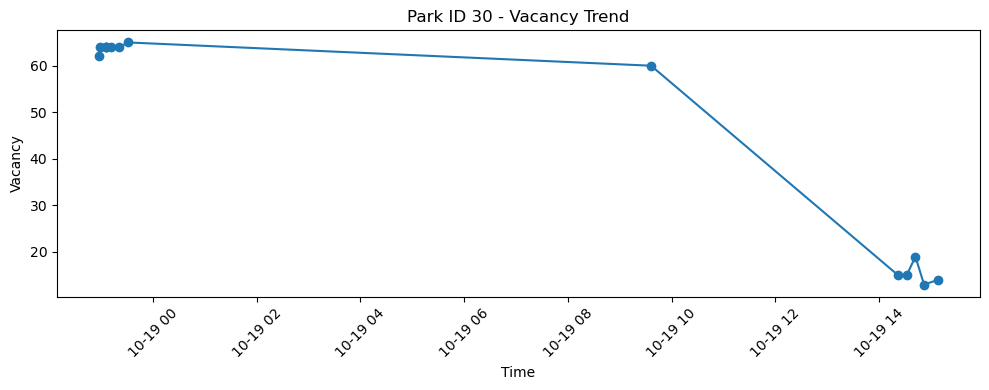

In [29]:
import matplotlib.pyplot as plt

# 只取 park_id = 30 的數據
df_30 = df_sample[df_sample["park_id"] == "30"].copy()
df_30["collected_at"] = pd.to_datetime(df_30["collected_at"])

plt.figure(figsize=(10, 4))
plt.plot(df_30["collected_at"], df_30["vacancy"], marker="o")
plt.title("Park ID 30 - Vacancy Trend")
plt.xlabel("Time")
plt.ylabel("Vacancy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
conn = sqlite3.connect("parking.db")

query = """
SELECT collected_at, AVG(vacancy) as avg_vacancy, COUNT(*) as num_carparks
FROM vacancy_records
GROUP BY collected_at
ORDER BY collected_at
"""

df_avg = pd.read_sql_query(query, conn)
df_avg["collected_at"] = pd.to_datetime(df_avg["collected_at"])
print(df_avg)

conn.close()

          collected_at  avg_vacancy  num_carparks
0  2026-10-18 22:57:22    35.093960           149
1  2026-10-18 22:58:16    34.489933           149
2  2026-10-18 23:05:16    34.932886           149
3  2026-10-18 23:05:26    34.926174           149
4  2026-10-18 23:05:37    34.932886           149
5  2026-10-18 23:11:01    34.637584           149
6  2026-10-18 23:21:03    35.389262           149
7  2026-10-18 23:31:04    35.630872           149
8  2026-10-19 09:36:19    33.100671           149
9  2026-10-19 14:22:09    23.677852           149
10 2026-10-19 14:32:11    25.147651           149
11 2026-10-19 14:42:12    25.711409           149
12 2026-10-19 14:52:13    25.281879           149
13 2026-10-19 15:08:24    24.496644           149


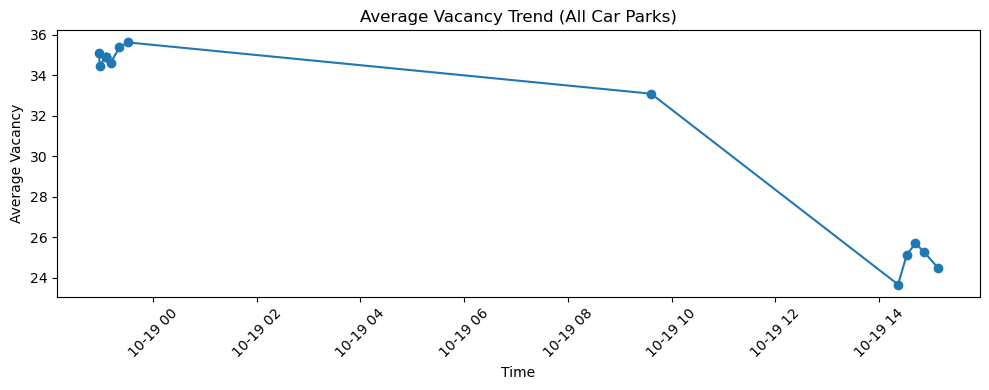

In [31]:
plt.figure(figsize=(10, 4))
plt.plot(df_avg["collected_at"], df_avg["avg_vacancy"], marker="o")
plt.title("Average Vacancy Trend (All Car Parks)")
plt.xlabel("Time")
plt.ylabel("Average Vacancy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
weather_url = "https://data.weather.gov.hk/weatherAPI/opendata/weather.php"
weather_params = {
    "dataType": "rhrread",
    "lang": "tc"
}

weather_response = requests.get(weather_url, params=weather_params, timeout=30)
print("Status Code:", weather_response.status_code)

if weather_response.status_code == 200:
    weather_data = weather_response.json()
    print("更新時間:", weather_data.get("updateTime"))
    # 顯示溫度與降雨簡要
    temp = weather_data.get("temperature", {}).get("data", [])
    print("部分溫度數據:", temp[:2] if temp else "無")
else:
    print("請求失敗")

Status Code: 200
更新時間: 2026-10-19T15:02:00+08:00
部分溫度數據: [{'place': '京士柏', 'value': 31, 'unit': 'C'}, {'place': '香港天文台', 'value': 32, 'unit': 'C'}]


In [33]:
rainfall = weather_data.get("rainfall", {}).get("data", [])
print("降雨數據筆數:", len(rainfall))

# 顯示前 5 個地區的降雨
for item in rainfall[:5]:
    print(f"{item.get('place')}: {item.get('max')} mm")

降雨數據筆數: 18
中西區: 0 mm
東區: 0 mm
葵青: 0 mm
離島區: 0 mm
北區: 0 mm
